# 04. Признаки и оптимизация модели

После сравнения базовых моделей мы остановились на градиентном бустинге и проверили два возможных пути улучшения: изменение состава признаков и подбор гиперпараметров. Результат каждого изменения оценивается по средней MAE (средняя абсолютная ошибка) на внешних временных разбиениях.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit

from src.data_preparation import RANDOM_STATE, ROOT
from src.evaluation import RegressionExperiment
from src.features import ALL_FEATURES, LAG_FEATURES, prepare_feature_dataset
from src.pipelines import build_boosting_regressor

feature_dataset = prepare_feature_dataset()
experiment = RegressionExperiment(feature_dataset)
features = experiment.features
target = experiment.target
splits = experiment.splits

## Влияние признаков

Сначала оставили только лаг на 15 минут, затем добавили суточный и недельный лаги, а после них — календарные признаки. Это позволяет проверить, какую пользу даёт история на разных временных расстояниях и дополняет ли её календарь. Настройки модели и временные разбиения во всех трёх вариантах одинаковы.

In [2]:
experiment.evaluate_regressor("Последний интервал", LAG_FEATURES[:1])
feature_sets = [
    ("Бустинг · лаг 15 мин", LAG_FEATURES[:1]),
    ("Бустинг · три лага", LAG_FEATURES),
    ("Бустинг · лаги и календарь", ALL_FEATURES),
]
for regressor_name, feature_names in feature_sets:
    boosting_regressor = build_boosting_regressor(feature_names)
    experiment.evaluate_regressor(regressor_name, feature_names, boosting_regressor)
display(experiment.summarize_results().round(3))

,MAE,MAE_std,RMSE,RMSE_std,R2,R2_std
regressor,,,,,,
Последний интервал,5.835,0.444,13.079,0.875,0.828,0.018
Бустинг · лаг 15 мин,6.059,0.374,12.560,0.901,0.841,0.018
Бустинг · три лага,5.756,0.621,11.478,1.055,0.867,0.020
Бустинг · лаги и календарь,4.808,0.684,9.773,1.097,0.903,0.018


## Подбор гиперпараметров

Затем проверили, можно ли улучшить базовую конфигурацию бустинга подбором настроек. С помощью `GridSearchCV` (перебор сочетаний параметров по сетке с кросс-валидацией) перебрали восемь сочетаний параметров, а с помощью `RandomizedSearchCV` (случайный поиск параметров с кросс-валидацией) — восемь сочетаний из расширенного пространства поиска. В обоих случаях настройки выбирали по MAE на внутренних временных разбиениях, а результат сравнивали с базовой конфигурацией на внешних.

In [3]:
inner_splits = TimeSeriesSplit(n_splits=3)
parameter_grid = {
    "regressor__learning_rate": [0.05, 0.1],
    "regressor__max_leaf_nodes": [15, 31],
    "regressor__min_samples_leaf": [20, 60],
}
parameter_space = {
    "regressor__learning_rate": [0.04, 0.07, 0.10, 0.15],
    "regressor__max_leaf_nodes": [8, 15, 31, 45],
    "regressor__min_samples_leaf": [15, 30, 60, 100],
}
search_settings = dict(
    scoring="neg_mean_absolute_error", cv=inner_splits, n_jobs=1, error_score="raise"
)
grid_search_regressor = GridSearchCV(
    build_boosting_regressor(ALL_FEATURES), parameter_grid, **search_settings
)
experiment.evaluate_regressor("Бустинг · сетка", ALL_FEATURES, grid_search_regressor)
random_search_regressor = RandomizedSearchCV(
    build_boosting_regressor(ALL_FEATURES),
    parameter_space,
    n_iter=8,
    random_state=RANDOM_STATE,
    **search_settings,
)
experiment.evaluate_regressor(
    "Бустинг · случайный поиск", ALL_FEATURES, random_search_regressor
)
display(pd.DataFrame(experiment.hyperparameter_choices).round(3))

,regressor,fold,params,inner_MAE
0,Бустинг · сетка,1,"{""regressor__learning_rate"": 0.05, ""regressor_...",9.074
1,Бустинг · сетка,2,"{""regressor__learning_rate"": 0.1, ""regressor__...",6.375
2,Бустинг · сетка,3,"{""regressor__learning_rate"": 0.1, ""regressor__...",5.665
3,Бустинг · сетка,4,"{""regressor__learning_rate"": 0.1, ""regressor__...",5.130
4,Бустинг · сетка,5,"{""regressor__learning_rate"": 0.1, ""regressor__...",4.919
5,Бустинг · случайный поиск,1,"{""regressor__min_samples_leaf"": 15, ""regressor...",9.016
6,Бустинг · случайный поиск,2,"{""regressor__min_samples_leaf"": 15, ""regressor...",6.529
7,Бустинг · случайный поиск,3,"{""regressor__min_samples_leaf"": 15, ""regressor...",5.705
8,Бустинг · случайный поиск,4,"{""regressor__min_samples_leaf"": 15, ""regressor...",5.127
9,Бустинг · случайный поиск,5,"{""regressor__min_samples_leaf"": 15, ""regressor...",4.942


## Сравнение моделей

In [4]:
fold_scores = pd.DataFrame(experiment.scores)
comparison_table = fold_scores.groupby("regressor", sort=False).agg(
    MAE=("MAE", "mean"),
    MAE_std=("MAE", "std"),
    RMSE=("RMSE", "mean"),
    RMSE_std=("RMSE", "std"),
    R2=("R2", "mean"),
    R2_std=("R2", "std"),
)
baseline_mae = comparison_table.loc["Последний интервал", "MAE"]
comparison_table["MAE_kW"] = 4 * comparison_table.MAE
comparison_table["gain_pct"] = 100 * (1 - comparison_table.MAE / baseline_mae)
comparison_table = comparison_table.sort_values("MAE")
winning_regressor_name = comparison_table.index[0]
assert fold_scores.groupby("regressor").size().eq(5).all()

display(comparison_table.round(3))
print(
    f"Лидер по средней MAE: {winning_regressor_name}; выигрыш к ориентиру {comparison_table.loc[winning_regressor_name, 'gain_pct']:.1f}%."
)
experiment.save_results("comparison", summary=comparison_table)

,MAE,MAE_std,RMSE,RMSE_std,R2,R2_std,MAE_kW,gain_pct
regressor,,,,,,,,
Бустинг · лаги и календарь,4.808,0.684,9.773,1.097,0.903,0.018,19.234,17.591
Бустинг · случайный поиск,4.828,0.668,9.675,1.009,0.906,0.016,19.311,17.261
Бустинг · сетка,4.869,0.733,9.748,1.094,0.904,0.018,19.474,16.560
Бустинг · три лага,5.756,0.621,11.478,1.055,0.867,0.020,23.026,1.344
Последний интервал,5.835,0.444,13.079,0.875,0.828,0.018,23.340,0.000
Бустинг · лаг 15 мин,6.059,0.374,12.560,0.901,0.841,0.018,24.238,-3.848


Лидер по средней MAE: Бустинг · лаги и календарь; выигрыш к ориентиру 17.6%.


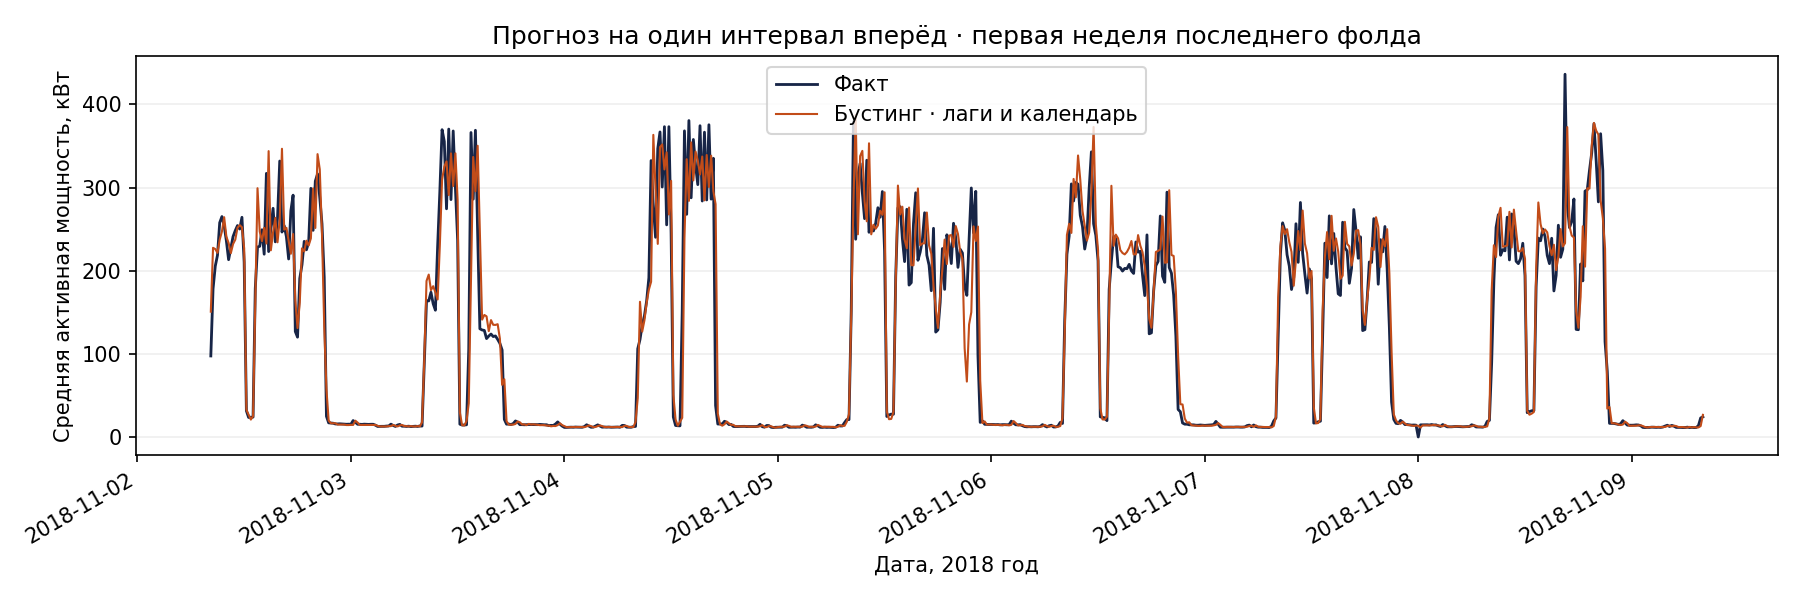

In [5]:
from IPython.display import Image

# Первая полная неделя последнего проверочного фолда. Период фиксирован до выбора модели.
last_test_indices = splits[-1][1]
forecast_week = features.index[last_test_indices[: 7 * 96]]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(
    forecast_week,
    4 * target.loc[forecast_week],
    label="Факт",
    linewidth=1.35,
    color="#172547",
)
ax.plot(
    forecast_week,
    4 * experiment.predictions[winning_regressor_name].loc[forecast_week],
    label=winning_regressor_name,
    linewidth=1,
    color="#c24c19",
)
ax.set(
    ylabel="Средняя активная мощность, кВт",
    xlabel="Дата, 2018 год",
    title="Прогноз на один интервал вперёд · первая неделя последнего фолда",
)
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.autofmt_xdate()
fig.tight_layout()
(ROOT / "results/figures").mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / "results/figures/forecast_week.png", dpi=150)
plt.close(fig)
display(Image(filename=str(ROOT / "results/figures/forecast_week.png")))

## Результаты и ограничения

Бустинг с тремя лагами и календарными признаками достигает MAE **4,808 ± 0,684 кВт·ч**. Ошибка прогноза по последнему наблюдению составляет **5,835 кВт·ч**; относительное снижение MAE — **17,6%**. В пересчёте на среднюю активную мощность MAE составляет **19,23 кВт**.

Добавление суточного и недельного лагов снижает MAE с 6,059 до 5,756 кВт·ч; добавление календаря — до 4,808 кВт·ч. Вклад отдельных календарных признаков не оценивался.

Стандартный бустинг даёт MAE **4,808 кВт·ч**. Случайный поиск даёт MAE **4,828 кВт·ч** — ухудшение на **0,019 кВт·ч (примерно 0,4%)**; поиск по сетке — **4,869 кВт·ч**, ухудшение на **0,060 кВт·ч (примерно 1,3%)**. Разницы и проценты рассчитаны до округления MAE в таблице относительно стандартного бустинга. Таким образом, подбор гиперпараметров не улучшил основную метрику, поэтому оставлена стандартная модель — базовая конфигурация бустинга. Случайный поиск снижает дополнительную метрику RMSE (корень из средней квадратичной ошибки) с 9,773 до 9,675 кВт·ч, но это не меняет выбор по MAE.

Результаты относятся к одному предприятию и данным 2018 года. Оценка предполагает обновление прогноза каждые 15 минут и немедленную доступность завершённых измерений. Для другого горизонта или задержки измерений требуется отдельная проверка.